In [2]:

from google.colab import files
import zipfile
import os

# Upload your GitHub repository ZIP
uploaded = files.upload()

# Extract the uploaded ZIP
zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content')

# Enter the extracted repository folder
%cd /content/Fraud-and-Credit-Risk-Classification-main

# Check project files
print(os.listdir())


Saving Fraud-and-Credit-Risk-Classification-main.zip to Fraud-and-Credit-Risk-Classification-main.zip
/content/Fraud-and-Credit-Risk-Classification-main
['data', 'person_a', 'requirements.txt', 'results', '.gitignore', 'common']


In [3]:

# Step 3: Inspect the shared data pipeline

import inspect
import common.data as data

print("AVAILABLE FUNCTIONS:")
for name, obj in inspect.getmembers(data, inspect.isfunction):
    if obj.__module__ == data.__name__:
        print("-", name)

print("\nGERMAN CREDIT LOADER:")
print(inspect.getsource(data.load_german))

print("\nGERMAN CREDIT CV SPLITS:")
print(inspect.getsource(data.german_cv_splits))


AVAILABLE FUNCTIONS:
- german_cv_splits
- load_fraud
- load_german
- random_split
- temporal_split

GERMAN CREDIT LOADER:
def load_german(path=None):
    """Load german.data (the categorical version) with readable column names.

    Adds a binary column 'bad' (1 = bad credit risk) and drops the raw label.
    """
    path = path or DATA_DIR / "german.data"
    df = pd.read_csv(path, sep=" ", header=None, names=GERMAN_COLS)
    df[GERMAN_TARGET] = (df["label"] == 2).astype(int)
    return df.drop(columns="label")


GERMAN CREDIT CV SPLITS:
def german_cv_splits(df, n_splits=5, n_repeats=5, seed=0):
    """Repeated stratified k-fold. Yields (repeat, fold, train_idx, test_idx)."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    for i, (tr, te) in enumerate(rskf.split(df, df[GERMAN_TARGET])):
        yield i // n_splits, i % n_splits, tr, te



In [4]:

# Step 4: Load German Credit dataset

from common.data import load_german, german_cv_splits

# Load dataset using teammate's function
df = load_german()

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nTarget distribution:")
print(df["bad"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

# Generate the same cross-validation splits
splits = list(german_cv_splits(df))

print("\nNumber of CV splits:", len(splits))

# Inspect first split
repeat, fold, train_idx, test_idx = splits[0]

print("Repeat:", repeat)
print("Fold:", fold)
print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))


Dataset shape: (1000, 21)

First 5 rows:


,checking_status,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,bad
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1



Target distribution:
bad
0    700
1    300
Name: count, dtype: int64

Missing values: 0

Number of CV splits: 25
Repeat: 0
Fold: 0
Training samples: 800
Testing samples: 200


In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Use the first shared CV fold
repeat, fold, train_idx, test_idx = splits[0]

X = df.drop(columns=["bad"])
y = df["bad"]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Identify categorical and numerical features
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))

# Preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_cols)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Create inner validation split for Keras
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_processed,
    y_train.to_numpy(),
    test_size=0.2,
    stratify=y_train,
    random_state=0
)

print("\nTraining shape:", X_fit.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test_processed.shape)


Categorical features: 13
Numerical features: 7

Training shape: (640, 61)
Validation shape: (160, 61)
Testing shape: (200, 61)


In [6]:

# Step 6: Build and train the Keras model

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build neural network
model = keras.Sequential([
    keras.Input(shape=(X_fit.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(
            curve="PR",
            name="pr_auc"
        )
    ]
)

# Stop training when validation loss stops improving
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train
history = model.fit(
    X_fit.astype("float32"),
    np.asarray(y_fit).astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        np.asarray(y_val).astype("float32")
    ),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining completed!")


Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.5975 - pr_auc: 0.4002 - roc_auc: 0.6232 - val_loss: 0.5581 - val_pr_auc: 0.5835 - val_roc_auc: 0.7640
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5385 - pr_auc: 0.5728 - roc_auc: 0.7726 - val_loss: 0.5332 - val_pr_auc: 0.5563 - val_roc_auc: 0.7666
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4987 - pr_auc: 0.6418 - roc_auc: 0.8105 - val_loss: 0.5188 - val_pr_auc: 0.5648 - val_roc_auc: 0.7723
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4700 - pr_auc: 0.6763 - roc_auc: 0.8302 - val_loss: 0.5112 - val_pr_auc: 0.5779 - val_roc_auc: 0.7751
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4485 - pr_auc: 0.7065 - roc_auc: 0.8449 - val_loss: 0.5079 - val_pr_auc: 0.5915 - val_roc_auc: 0.7786
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4310 - pr_auc: 0.7331 - roc_auc: 0.8569 - val_loss: 0.5070 - val_pr_auc: 0.5964 - val_roc_auc: 0.7782
Epoch 7/100
20/20 ━━━

In [7]:

# Step 7: Evaluate Keras on the test set

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    classification_report
)

# Predict probability of bad credit
y_prob = model.predict(
    X_test_processed.astype("float32"),
    verbose=0
).ravel()

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate metrics
print("=== KERAS: GERMAN CREDIT (FOLD 1) ===")
print("PR-AUC:", round(
    average_precision_score(y_test, y_prob), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob), 4
))
print("Brier Score:", round(
    brier_score_loss(y_test, y_prob), 4
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, y_prob)), 4
))
print("MAE:", round(
    mean_absolute_error(y_test, y_prob), 4
))
print("Accuracy:", round(
    accuracy_score(y_test, y_pred), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


=== KERAS: GERMAN CREDIT (FOLD 1) ===
PR-AUC: 0.574
ROC-AUC: 0.7951
Brier Score: 0.1678
RMSE: 0.4097
MAE: 0.3212
Accuracy: 0.75

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.91      0.84       140
           1       0.64      0.38      0.48        60

    accuracy                           0.75       200
   macro avg       0.71      0.65      0.66       200
weighted avg       0.73      0.75      0.73       200



In [8]:

# Step 8: Compare classification thresholds

from sklearn.metrics import confusion_matrix

def evaluate_threshold(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    # Missed bad borrower = 5
    # Incorrectly rejected good borrower = 1
    total_cost = 5 * fn + fp

    print(f"\nThreshold: {threshold:.4f}")
    print(f"Bad borrowers caught: {tp}")
    print(f"Bad borrowers missed: {fn}")
    print(f"Good borrowers incorrectly rejected: {fp}")
    print(f"Recall for bad borrowers: {tp / (tp + fn):.3f}")
    print(f"Total cost: {total_cost}")
    print(f"Average cost per applicant: {total_cost / len(y_true):.4f}")

evaluate_threshold(y_test, y_prob, 0.5)
evaluate_threshold(y_test, y_prob, 1/6)



Threshold: 0.5000
Bad borrowers caught: 23
Bad borrowers missed: 37
Good borrowers incorrectly rejected: 13
Recall for bad borrowers: 0.383
Total cost: 198
Average cost per applicant: 0.9900

Threshold: 0.1667
Bad borrowers caught: 54
Bad borrowers missed: 6
Good borrowers incorrectly rejected: 62
Recall for bad borrowers: 0.900
Total cost: 92
Average cost per applicant: 0.4600


In [9]:

# Step 9: Save first-fold Keras results

import pandas as pd
import os

os.makedirs("person_b/results", exist_ok=True)

# Save test predictions
predictions_df = pd.DataFrame({
    "repeat": repeat,
    "fold": fold,
    "actual": y_test.to_numpy(),
    "predicted_probability": y_prob,
    "prediction_05": (y_prob >= 0.5).astype(int),
    "prediction_cost": (y_prob >= 1/6).astype(int)
})

predictions_df.to_csv(
    "person_b/results/keras_german_fold1_predictions.csv",
    index=False
)

# Save summary metrics
summary_df = pd.DataFrame([{
    "model": "Keras",
    "dataset": "German Credit",
    "repeat": repeat,
    "fold": fold,
    "pr_auc": 0.574,
    "roc_auc": 0.7951,
    "brier": 0.1678,
    "rmse": 0.4097,
    "mae": 0.3212,
    "cost_threshold_05": 198,
    "cost_threshold_0167": 92
}])

summary_df.to_csv(
    "person_b/results/keras_german_fold1_metrics.csv",
    index=False
)

print("First-fold results saved successfully!")
print(os.listdir("person_b/results"))


First-fold results saved successfully!
['keras_german_fold1_metrics.csv', 'keras_german_fold1_predictions.csv']


In [10]:

# STEP 10: Full 25-fold Keras CV — German Credit

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from common.data import load_german, german_cv_splits
from common.metrics import all_metrics, german_cost

os.makedirs("person_b/results", exist_ok=True)

df = load_german()
X = df.drop(columns=["bad"])
y = df["bad"].to_numpy()

cat_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

all_results = []
all_predictions = []

# Fresh neural network for each fold
def build_keras_model(input_dim):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="binary_crossentropy"
    )
    return model

# 5 folds x 5 repeats = 25 experiments
for repeat, fold, train_idx, test_idx in german_cv_splits(df):

    seed = repeat * 5 + fold

    # Separate inner training and validation BEFORE preprocessing
    fit_idx, val_idx = train_test_split(
        train_idx,
        test_size=0.2,
        stratify=y[train_idx],
        random_state=seed
    )

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), cat_cols)
    ])

    X_fit = preprocessor.fit_transform(
        X.iloc[fit_idx]
    ).astype("float32")

    X_val = preprocessor.transform(
        X.iloc[val_idx]
    ).astype("float32")

    X_test = preprocessor.transform(
        X.iloc[test_idx]
    ).astype("float32")

    y_fit = y[fit_idx]
    y_val = y[val_idx]
    y_test_fold = y[test_idx]

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + seed)

    model = build_keras_model(X_fit.shape[1])

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_fit, y_fit,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    probabilities = model.predict(
        X_test, verbose=0
    ).ravel()

    # Use the team's shared evaluation functions
    metrics = all_metrics(y_test_fold, probabilities)

    metrics["repeat"] = repeat
    metrics["fold"] = fold
    metrics["model"] = "Keras"
    metrics["dataset"] = "German Credit"
    metrics["epochs"] = len(history.history["loss"])

    metrics["cost_05"] = german_cost(
        y_test_fold, probabilities >= 0.5
    )

    metrics["cost_0167"] = german_cost(
        y_test_fold, probabilities >= 1/6
    )

    all_results.append(metrics)

    for idx, actual, prob in zip(
        test_idx, y_test_fold, probabilities
    ):
        all_predictions.append({
            "repeat": repeat,
            "fold": fold,
            "row_index": int(idx),
            "actual": int(actual),
            "predicted_probability": float(prob)
        })

    print(
        f"Repeat {repeat+1}/5 | Fold {fold+1}/5 "
        f"| PR-AUC: {metrics['pr_auc']:.4f} "
        f"| Brier: {metrics['brier']:.4f} "
        f"| Cost: {metrics['cost_0167']:.4f}"
    )

    del model
    gc.collect()

# Save results
results_df = pd.DataFrame(all_results)
predictions_df = pd.DataFrame(all_predictions)

results_df.to_csv(
    "person_b/results/keras_german_25fold_metrics.csv",
    index=False
)

predictions_df.to_csv(
    "person_b/results/keras_german_25fold_predictions.csv",
    index=False
)

# Summarize
summary_cols = [
    "pr_auc", "roc_auc", "brier",
    "rmse", "mae", "r2",
    "cost_05", "cost_0167"
]

print("\n=== FINAL KERAS GERMAN CREDIT RESULTS ===")
print(
    results_df[summary_cols]
    .agg(["mean", "std"])
    .round(4)
    .to_string()
)

print("\nCompleted folds:", len(results_df))
print("Results saved successfully!")


Repeat 1/5 | Fold 1/5 | PR-AUC: 0.5765 | Brier: 0.1675 | Cost: 0.4400


Repeat 1/5 | Fold 2/5 | PR-AUC: 0.6464 | Brier: 0.1639 | Cost: 0.4850


Repeat 1/5 | Fold 3/5 | PR-AUC: 0.7093 | Brier: 0.1443 | Cost: 0.4900
Repeat 1/5 | Fold 4/5 | PR-AUC: 0.5647 | Brier: 0.1834 | Cost: 0.6750
Repeat 1/5 | Fold 5/5 | PR-AUC: 0.5701 | Brier: 0.1678 | Cost: 0.4800
Repeat 2/5 | Fold 1/5 | PR-AUC: 0.6157 | Brier: 0.1613 | Cost: 0.5750
Repeat 2/5 | Fold 2/5 | PR-AUC: 0.5998 | Brier: 0.1672 | Cost: 0.5150
Repeat 2/5 | Fold 3/5 | PR-AUC: 0.5344 | Brier: 0.1770 | Cost: 0.6100
Repeat 2/5 | Fold 4/5 | PR-AUC: 0.7766 | Brier: 0.1396 | Cost: 0.4800
Repeat 2/5 | Fold 5/5 | PR-AUC: 0.5002 | Brier: 0.1961 | Cost: 0.6200
Repeat 3/5 | Fold 1/5 | PR-AUC: 0.5518 | Brier: 0.1760 | Cost: 0.6300
Repeat 3/5 | Fold 2/5 | PR-AUC: 0.6654 | Brier: 0.1597 | Cost: 0.5250
Repeat 3/5 | Fold 3/5 | PR-AUC: 0.5682 | Brier: 0.1710 | Cost: 0.5150
Repeat 3/5 | Fold 4/5 | PR-AUC: 0.6309 | Brier: 0.1690 | Cost: 0.5950
Repeat 3/5 | Fold 5/5 | PR-AUC: 0.6513 | Brier: 0.1622 | Cost: 0.5600
Repeat 4/5 | Fold 1/5 | PR-AUC: 0.6197 | Brier: 0.1546 | Cost: 0.4950
Repeat 4/5 | Fold 2/

In [11]:

# Step 11: Download completed Keras German Credit results

from google.colab import files

files.download(
    "person_b/results/keras_german_25fold_metrics.csv"
)

files.download(
    "person_b/results/keras_german_25fold_predictions.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

import os
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    PrecisionRecallDisplay,
    average_precision_score,
    brier_score_loss
)

from common.data import load_fraud, temporal_split
from common.metrics import all_metrics, bootstrap_ci
from person_a.features import base_features

os.makedirs("person_b/results/figures", exist_ok=True)

# Load and deduplicate using shared pipeline
fraud_df = load_fraud()

print("Dataset shape:", fraud_df.shape)
print("Duplicates removed:",
      fraud_df.attrs["n_duplicates_dropped"])

print("\nClass distribution:")
print(fraud_df["Class"].value_counts())

# Use exactly the same temporal split as Person A
train_idx, val_idx, test_idx = temporal_split(fraud_df)

# Same baseline features as Person A
X = base_features(fraud_df)
y = fraud_df["Class"].to_numpy().astype(int)

# Fit scaler ONLY on training data
scaler = StandardScaler()

X_train = scaler.fit_transform(
    X.iloc[train_idx]
).astype("float32")

X_val = scaler.transform(
    X.iloc[val_idx]
).astype("float32")

X_test = scaler.transform(
    X.iloc[test_idx]
).astype("float32")

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

print("\nTraining:", X_train.shape,
      "Frauds:", y_train.sum())
print("Validation:", X_val.shape,
      "Frauds:", y_val.sum())
print("Testing:", X_test.shape,
      "Frauds:", y_test.sum())


Dataset shape: (99618, 31)
Duplicates removed: 381

Class distribution:
Class
0    99395
1      223
Name: count, dtype: int64

Training: (59272, 29) Frauds: 162
Validation: (10460, 29) Frauds: 13
Testing: (29886, 29) Frauds: 48


In [13]:

# Keras fraud model — 5 training seeds

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("Class weights:", class_weights)

def build_fraud_model(input_dim):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.1),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(
                name="pr_auc", curve="PR"
            )
        ]
    )

    return model

fraud_results = []
fraud_predictions = []
training_histories = []

for seed in range(5):

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + seed)

    model = build_fraud_model(X_train.shape[1])

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    start = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        class_weight=class_weights,
        epochs=60,
        batch_size=256,
        callbacks=[early_stop],
        verbose=0
    )

    training_seconds = time.time() - start

    # Test probabilities
    probabilities = model.predict(
        X_test, batch_size=1024, verbose=0
    ).ravel()

    metrics = all_metrics(y_test, probabilities)

    metrics.update({
        "model": "keras",
        "dataset": "fraud",
        "split": "temporal",
        "features": "base",
        "seed": seed,
        "epochs": len(history.history["loss"]),
        "train_seconds": training_seconds,
        "test_frauds": int(y_test.sum())
    })

    fraud_results.append(metrics)
    fraud_predictions.append(probabilities)

    training_histories.append({
        "seed": seed,
        "loss": history.history["loss"],
        "val_loss": history.history["val_loss"]
    })

    print(
        f"Seed {seed} | "
        f"PR-AUC: {metrics['pr_auc']:.4f} | "
        f"ROC-AUC: {metrics['roc_auc']:.4f} | "
        f"Brier: {metrics['brier']:.4f} | "
        f"Time: {training_seconds:.1f}s"
    )

    if seed == 0:
        model.save(
            "person_b/results/keras_fraud_model.keras"
        )

    del model
    gc.collect()

fraud_results_df = pd.DataFrame(fraud_results)

fraud_results_df.to_csv(
    "person_b/results/keras_fraud_runs.csv",
    index=False
)

fraud_predictions = np.array(fraud_predictions)

np.savez_compressed(
    "person_b/results/keras_fraud_predictions.npz",
    test_idx=test_idx,
    y_test=y_test,
    probabilities=fraud_predictions
)

print("\n=== SUMMARY ACROSS 5 SEEDS ===")

cols = [
    "pr_auc", "roc_auc",
    "brier", "rmse", "mae", "r2"
]

print(
    fraud_results_df[cols]
    .agg(["mean", "std"])
    .round(4)
    .to_string()
)


Class weights: {0: 0.5013703265098968, 1: 182.93827160493828}
Seed 0 | PR-AUC: 0.8771 | ROC-AUC: 0.9645 | Brier: 0.0011 | Time: 27.9s
Seed 1 | PR-AUC: 0.8472 | ROC-AUC: 0.9524 | Brier: 0.0008 | Time: 25.0s
Seed 2 | PR-AUC: 0.8581 | ROC-AUC: 0.9557 | Brier: 0.0008 | Time: 34.4s
Seed 3 | PR-AUC: 0.8662 | ROC-AUC: 0.9551 | Brier: 0.0009 | Time: 22.5s
Seed 4 | PR-AUC: 0.8632 | ROC-AUC: 0.9555 | Brier: 0.0009 | Time: 21.9s

=== SUMMARY ACROSS 5 SEEDS ===
      pr_auc  roc_auc   brier    rmse     mae      r2
mean  0.8624   0.9566  0.0009  0.0296  0.0019  0.4498
std   0.0109   0.0046  0.0001  0.0020  0.0004  0.0757


In [14]:

# Compare Keras against Person A's models

person_a_results = pd.read_csv(
    "results/person_a/fraud_runs.csv"
)

# Same temporal split and base features
baseline = person_a_results[
    (person_a_results["split"] == "temporal") &
    (person_a_results["features"] == "base")
].copy()

keras_comparison = fraud_results_df.copy()

comparison = pd.concat(
    [
        baseline[[
            "model", "pr_auc",
            "roc_auc", "brier",
            "rmse", "mae"
        ]],
        keras_comparison[[
            "model", "pr_auc",
            "roc_auc", "brier",
            "rmse", "mae"
        ]]
    ],
    ignore_index=True
)

summary = comparison.groupby("model").agg(
    ["mean", "std"]
)

print("=== FRAMEWORK COMPARISON ===")
display(summary.round(4))

summary.to_csv(
    "person_b/results/keras_vs_person_a.csv"
)

print(
    "\nNote: Keras uses 5 seeds; "
    "Person A uses 10 seeds."
)


=== FRAMEWORK COMPARISON ===


pr_auc         roc_auc           brier            rmse          \
           mean     std    mean     std    mean     std    mean     std   
model                                                                     
fastai   0.8546  0.0166  0.9621  0.0164  0.0004  0.0001  0.0209  0.0014   
keras    0.8624  0.0109  0.9566  0.0046  0.0009  0.0001  0.0296  0.0020   
xgboost  0.8754  0.0060  0.9752  0.0038  0.0004  0.0000  0.0191  0.0004   

            mae          
           mean     std  
model                    
fastai   0.0033  0.0002  
keras    0.0019  0.0004  
xgboost  0.0007  0.0001


Note: Keras uses 5 seeds; Person A uses 10 seeds.


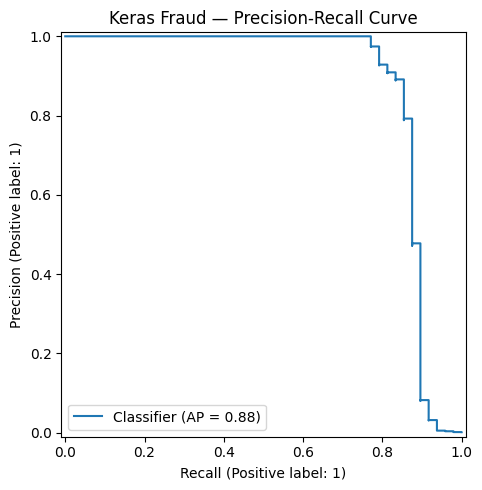

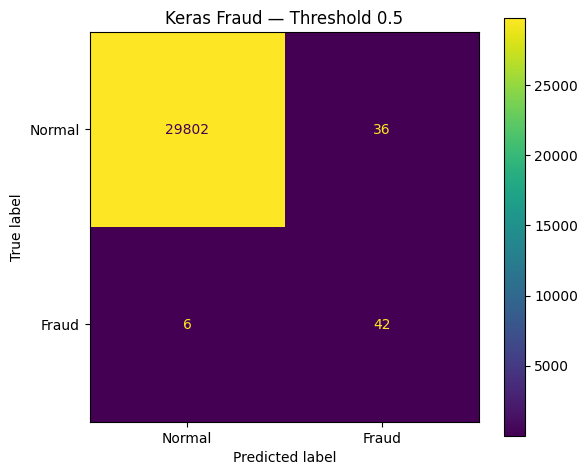

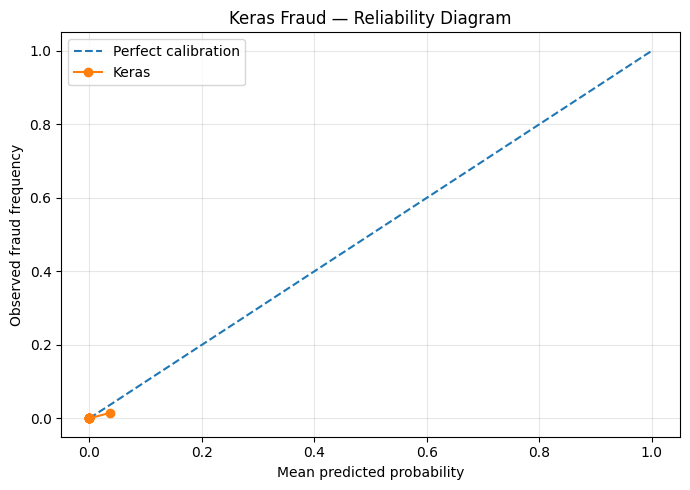

All three figures saved.


In [15]:

# Fraud evaluation plots

from sklearn.calibration import calibration_curve

# Use seed 0 for illustrative plots
p = fraud_predictions[0]

# 1. Precision-recall curve
fig, ax = plt.subplots(figsize=(7, 5))

PrecisionRecallDisplay.from_predictions(
    y_test, p, ax=ax
)

ax.set_title("Keras Fraud — Precision-Recall Curve")
plt.tight_layout()

plt.savefig(
    "person_b/results/figures/"
    "keras_fraud_pr_curve.png",
    dpi=200
)
plt.show()

# 2. Confusion matrix at threshold 0.5
predicted = (p >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, predicted,
    display_labels=["Normal", "Fraud"],
    ax=ax,
    values_format="d"
)

ax.set_title("Keras Fraud — Threshold 0.5")
plt.tight_layout()

plt.savefig(
    "person_b/results/figures/"
    "keras_fraud_confusion.png",
    dpi=200
)
plt.show()

# 3. Calibration plot
# Quantile bins are useful with highly skewed scores.
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    p,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    [0, 1], [0, 1],
    "--", label="Perfect calibration"
)

ax.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Keras"
)

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed fraud frequency")
ax.set_title("Keras Fraud — Reliability Diagram")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "person_b/results/figures/"
    "keras_fraud_calibration.png",
    dpi=200
)
plt.show()

print("All three figures saved.")


In [16]:

# Bootstrap 95% CI for seed 0

ci_low, ci_high = bootstrap_ci(
    y_test,
    fraud_predictions[0],
    average_precision_score,
    n_boot=1000,
    seed=42
)

point = average_precision_score(
    y_test, fraud_predictions[0]
)

print("Keras Fraud — Seed 0")
print(f"PR-AUC: {point:.4f}")
print(f"95% Bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}]")

ci_df = pd.DataFrame([{
    "model": "keras",
    "seed": 0,
    "metric": "pr_auc",
    "point": point,
    "ci_low": ci_low,
    "ci_high": ci_high
}])

ci_df.to_csv(
    "person_b/results/keras_fraud_ci.csv",
    index=False
)


Keras Fraud — Seed 0
PR-AUC: 0.8771
95% Bootstrap CI: [0.7838, 0.9543]


In [17]:

# Download all Person B results

import shutil
from google.colab import files

shutil.make_archive(
    "/content/person_b_results",
    "zip",
    root_dir="person_b/results"
)

files.download("/content/person_b_results.zip")

print("Results ZIP created successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Results ZIP created successfully!
